# Predicting 30-Day Hospital Readmissions
---

**Dataset:** Diabetes 130-US Hospitals (1999-2008), UCI Machine Learning Repository. About 101k inpatient encounters from 130 US hospitals.

**Goal:** Predict whether a patient will be readmitted within 30 days of discharge.

**Why it matters:** Readmissions are costly, and Medicare penalizes hospitals with high rates. If hospitals could spot high-risk patients before discharge, they could step in with extra follow-up

### Step 1: Load the data
**What:** Load the CSV into a pandas DataFrame and take a first look.

**Why:** Before cleaning or modeling, I need to know how big the data is, what the columns are, and what types they hold.

**What I found:** The dataset has 101,766 rows and 50 columns, and most columns are text. `info()` showed zero missing values, but `describe()` revealed that missing values are actually stored as "?" (weight is "?" in 98,569 rows). Also, `citoglipton` has only one value ("No") for every patient, so it adds nothing and will be dropped later.

In [33]:
from pathlib import Path
import pandas as pd
import numpy as np

# path to the data folder, relative to this notebook
DATA_DIR = Path("../data")

# main dataset: one row per hospital encounter
df = pd.read_csv(DATA_DIR / "diabetic_data.csv")
df.shape

(101766, 50)

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype
---  ------                    --------------   -----
 0   encounter_id              101766 non-null  int64
 1   patient_nbr               101766 non-null  int64
 2   race                      101766 non-null  str  
 3   gender                    101766 non-null  str  
 4   age                       101766 non-null  str  
 5   weight                    101766 non-null  str  
 6   admission_type_id         101766 non-null  int64
 7   discharge_disposition_id  101766 non-null  int64
 8   admission_source_id       101766 non-null  int64
 9   time_in_hospital          101766 non-null  int64
 10  payer_code                101766 non-null  str  
 11  medical_specialty         101766 non-null  str  
 12  num_lab_procedures        101766 non-null  int64
 13  num_procedures            101766 non-null  int64
 14  num_medications           10176

In [35]:
df.describe(include="all")

,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
count,1.017660e+05,1.017660e+05,101766,101766,101766,101766,101766.000000,101766.000000,101766.000000,101766.000000,...,101766,101766,101766,101766,101766,101766,101766,101766,101766,101766
unique,NaN,NaN,6,3,10,10,NaN,NaN,NaN,NaN,...,1,4,4,2,2,2,2,2,2,3
top,NaN,NaN,Caucasian,Female,[70-80),?,NaN,NaN,NaN,NaN,...,No,No,No,No,No,No,No,No,Yes,NO
freq,NaN,NaN,76099,54708,26068,98569,NaN,NaN,NaN,NaN,...,101766,47383,101060,101753,101765,101764,101765,54755,78363,54864
mean,1.652016e+08,5.433040e+07,NaN,NaN,NaN,NaN,2.024006,3.715642,5.754437,4.395987,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
std,1.026403e+08,3.869636e+07,NaN,NaN,NaN,NaN,1.445403,5.280166,4.064081,2.985108,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
min,1.252200e+04,1.350000e+02,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,1.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
25%,8.496119e+07,2.341322e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,1.000000,2.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
50%,1.523890e+08,4.550514e+07,NaN,NaN,NaN,NaN,1.000000,1.000000,7.000000,4.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
75%,2.302709e+08,8.754595e+07,NaN,NaN,NaN,NaN,3.000000,4.000000,7.000000,6.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


### Step 2: Find the real missing values
**What:** Reload the data treating "?" as missing, then count missing values per column.

**Why:** The dataset marks missing values with "?", so pandas didn't recognize them. I need to know which columns have gaps before deciding how to handle them.

**What I found:** Seven columns have real missing values: `weight` **(96.9%)**, `medical_specialty` **(49.1%)**, `payer_code` **(39.6%)**, `race` **(2.2%)**, `diag_3` **(1.4%)**, `diag_2` **(0.4%)**, and `diag_1` **(21 rows)**. All of them are text columns. A1Cresult and max_glu_serum first looked mostly missing, but their "None" value means "test not done," so I told pandas to keep it as a real category.

In [36]:
df = pd.read_csv(DATA_DIR / "diabetic_data.csv", na_values="?", keep_default_na=False, low_memory=False)

# percent missing per column, only showing columns that have any
missing_pct = (df.isna().sum() / len(df) * 100).round(1)
missing_pct[missing_pct > 0].sort_values(ascending=False)

weight               96.9
medical_specialty    49.1
payer_code           39.6
race                  2.2
diag_3                1.4
diag_2                0.4
dtype: float64

### Step 3: Handle missing values

**What:** Drop weight and fill the other missing text columns with "Unknown".

**Why:** Weight is too empty to use. For the rest, **"Unknown"** keeps the rows without making anything up. `diag_1` is the main diagnosis, so I just dropped the 21 rows missing it.

**What I found:** No missing values left.

In [37]:
# weight is ~97% missing, not worth keeping
df = df.drop(columns=["weight"])

# fill remaining missing text values with "Unknown"
fill_cols = ["medical_specialty", "payer_code", "race", "diag_2", "diag_3"]
df[fill_cols] = df[fill_cols].fillna("Unknown")

# drop 21 rows with no primary diagnosis (negligible loss)
df = df.dropna(subset=["diag_1"])

### Step 4: Remove rows that don't belong
**What:** Remove patients who died or went to hospice, and keep only each patient's first visit.

**Why:** Patients who died or went to hospice can't come back, so they'd skew the model. Repeat patients could end up in both train and test, so I kept each person's first visit.

**What I found:** Down to [99,343] rows after removing death/hospice, then [69,990] after dropping [29,353] repeat visits.

In [38]:
# discharge codes for patients who died or went to hospice bc they can't be readmitted
exclude_ids = [11, 13, 14, 19, 20, 21]

df = df[~df["discharge_disposition_id"].isin(exclude_ids)]
df.shape

(99323, 49)

In [39]:
# how many repeat visits are there?
df["patient_nbr"].duplicated().sum()

np.int64(29341)

In [40]:
# keep each patient's first encounter so the same person can't be in both train and test
df = df.sort_values("encounter_id").drop_duplicates(subset="patient_nbr", keep="first")
df.shape

(69982, 49)

### Step 5: Create the target and check class balance
**What:** Turn "readmitted" into a yes/no column for readmission within 30 days, then check how balanced it is.

**Why:** The original column has three values (<30, >30, NO), but the question is specifically about 30-day readmission, so I turned it into yes/no. Checking balance tells me whether accuracy will be misleading.

**What I found:** Only about 9% of patients were readmitted within 30 days. A model that always guesses "No" would achieve a 91% accuracy while catching zero readmissions.

In [41]:
# 1 = readmitted within 30 days, 0 = not (">30" and "NO" both count as 0)
df["readmit_30"] = (df["readmitted"] == "<30").astype(int)
df = df.drop(columns=["readmitted"])

In [42]:
# share of each class
df["readmit_30"].value_counts(normalize=True)

readmit_30
0    0.91022
1    0.08978
Name: proportion, dtype: float64

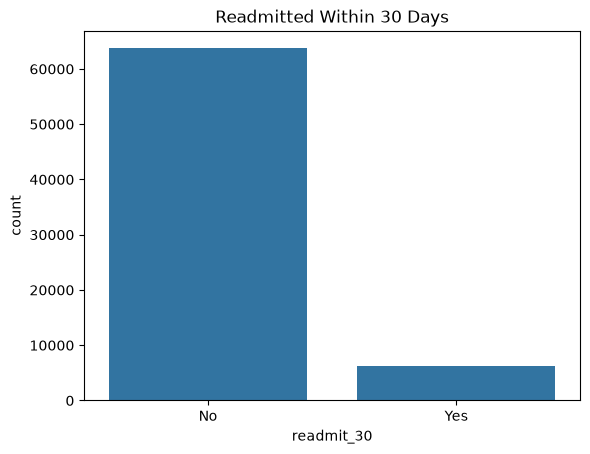

In [43]:
# bar chart of the class balance
import seaborn as sns
import matplotlib.pyplot as plt

sns.countplot(x="readmit_30", data=df)
plt.title("Readmitted Within 30 Days")
plt.xticks([0, 1], ["No", "Yes"])
plt.savefig("../images/class_balance.png", bbox_inches="tight")
plt.show()

### Step 6: Check feature distribution and outliers 

**What:** Plot histogram of the numeric columns and look for outliers.

**Why:** A few patients had extreme values, like 42 ER visits in a year. They're real patients, not errors, and likely the highest-risk ones, so I didn't want to just delete them. Capping at the 99th percentile keeps them but stops one extreme value from skewing the model.

**What I found:** Most columns look reasonable. Prior visits are almost always 0 with a long tail, and number_diagnoses spikes at 9, which I realized is because older systems only recorded up to 9. Capping changed under 1% of values per column, and the averages barely moved.

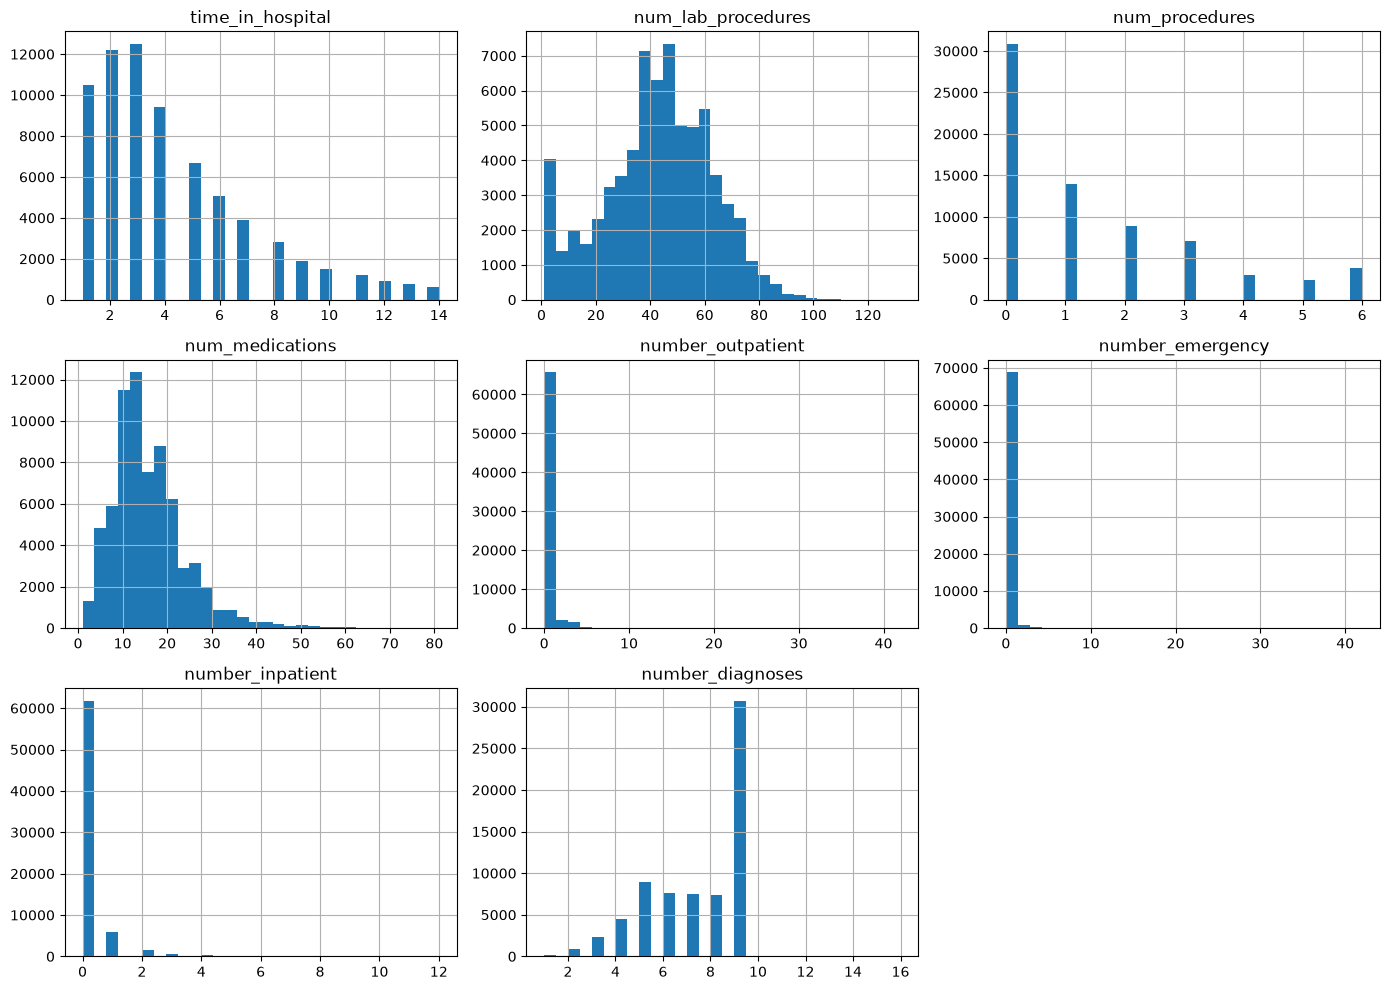

In [44]:
# Numeric features: counts and length of stay
num_cols = ["time_in_hospital", "num_lab_procedures", "num_procedures", "num_medications",
                "number_outpatient", "number_emergency", "number_inpatient", "number_diagnoses"]

# One histogram per column 
df[num_cols].hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.savefig("../images/numeric_features.png", bbox_inches="tight")
plt.show()


In [45]:
# Summary stats for numeric features
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
time_in_hospital,69982.0,4.273427,2.934111,1.0,2.0,3.0,6.0,14.0
num_lab_procedures,69982.0,42.875825,19.894788,1.0,31.0,44.0,57.0,132.0
num_procedures,69982.0,1.425552,1.757085,0.0,0.0,1.0,2.0,6.0
num_medications,69982.0,15.665485,8.287586,1.0,10.0,14.0,20.0,81.0
number_outpatient,69982.0,0.279615,1.064143,0.0,0.0,0.0,0.0,42.0
number_emergency,69982.0,0.103898,0.511839,0.0,0.0,0.0,0.0,42.0
number_inpatient,69982.0,0.176274,0.601574,0.0,0.0,0.0,0.0,12.0
number_diagnoses,69982.0,7.224229,2.001291,1.0,6.0,8.0,9.0,16.0


In [46]:
# Columns with long tails
cap_cols = ["num_lab_procedures", "num_medications", "number_outpatient",
            "number_emergency", "number_inpatient"]

# 99th percentile values for each column
caps = df[cap_cols].quantile(0.99)
caps



num_lab_procedures    85.0
num_medications       44.0
number_outpatient      4.0
number_emergency       2.0
number_inpatient       3.0
Name: 0.99, dtype: float64

In [47]:
# How many values get capped in each column
(df[cap_cols] > caps).sum()

num_lab_procedures    633
num_medications       683
number_outpatient     690
number_emergency      429
number_inpatient      433
dtype: int64

In [48]:
# cap extreme values instead of deleting patients 
df[cap_cols] = df[cap_cols].clip(upper=caps, axis=1)
df[cap_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
num_lab_procedures,69982.0,42.815224,19.748192,1.0,31.0,44.0,57.0,85.0
num_medications,69982.0,15.585508,7.943278,1.0,10.0,14.0,20.0,44.0
number_outpatient,69982.0,0.244177,0.742909,0.0,0.0,0.0,0.0,4.0
number_emergency,69982.0,0.090280,0.341966,0.0,0.0,0.0,0.0,2.0
number_inpatient,69982.0,0.164142,0.506788,0.0,0.0,0.0,0.0,3.0


### Step 7: Encode text columns
#### 7a: Drop columns that can't help
**What:** List every text column, then drop IDs and columns where almost every patient has the same value.

**Why:** ID columns just label rows, they don't predict anything. And if 99% of patients have the same value in a column, there's nothing for the model to learn from it.

**What I found:** 15 medication columns were at least 99% the same value, and 3 were identical for every patient, so I dropped them along with the two ID columns. Down to 32 columns.

In [49]:
# Every non-number column and how many categories each has
text_cols = df.select_dtypes(exclude="number").columns
df[text_cols].nunique().sort_values(ascending=False)

diag_3                      757
diag_2                      724
diag_1                      694
medical_specialty            71
payer_code                   18
age                          10
race                          6
glyburide-metformin           4
max_glu_serum                 4
A1Cresult                     4
metformin                     4
repaglinide                   4
nateglinide                   4
chlorpropamide                4
glimepiride                   4
glipizide                     4
glyburide                     4
rosiglitazone                 4
pioglitazone                  4
miglitol                      4
insulin                       4
gender                        3
acarbose                      3
tolbutamide                   2
acetohexamide                 2
troglitazone                  2
tolazamide                    2
change                        2
metformin-pioglitazone        2
glipizide-metformin           2
metformin-rosiglitazone       2
diabetes

In [50]:
# Share of the most common value in each text column 
top_share = df[text_cols].apply(lambda col: col.value_counts(normalize=True).iloc[0])

# Columns where 99% or more of patients have the same value
top_share[top_share > 0.99].sort_values(ascending=False)

glimepiride-pioglitazone    1.000000
citoglipton                 1.000000
examide                     1.000000
metformin-pioglitazone      0.999986
acetohexamide               0.999986
metformin-rosiglitazone     0.999971
troglitazone                0.999957
glipizide-metformin         0.999900
tolbutamide                 0.999757
miglitol                    0.999714
tolazamide                  0.999571
chlorpropamide              0.998985
acarbose                    0.997142
nateglinide                 0.992984
glyburide-metformin         0.992912
dtype: float64

In [51]:
# IDs indentify rows so they are not valuable for prediction 
# Near-constant columns have basically no variation to learn from 
near_constant = top_share[top_share > 0.99].index.tolist()
df = df.drop(columns=["encounter_id", "patient_nbr"] + near_constant)
df.shape

(69982, 32)

#### 7b: Simplify columns with too many categories
**What:** Group the 700+ diagnosis codes into body-system categories, and keep only the 10 most common medical specialties.

**Why:** The diagnosis columns had 700+ codes each, and one-hot encoding them would create thousands of mostly empty columns. Grouping codes by body system keeps the meaning in far fewer categories. Same idea for medical specialty: keep the top 10, lump the rest into Other.

**What I found:** Circulatory problems are the most common primary diagnosis by far, and diabetes is the main reason for only about 8% of stays. So these are diabetic patients admitted for all kinds of reasons.

In [52]:
# Group an ICD-9 diagnosis code into a body-system category
def group_icd9(code):
    if code == "Unknown":
        return "Unknown"
    if code.startswith(("V", "E")):  # Supplementary codes, not diseases
        return "Other"

    num = float(code)
    if 390 <= num < 460 or int(num) == 785:
        return "Circulatory"
    if 460 <= num < 520 or int(num) == 786:
        return "Respiratory"
    if 520 <= num < 580 or int(num) == 787:
        return "Digestive"
    if int(num) == 250:
        return "Diabetes"
    if 800 <= num < 1000:
        return "Injury"
    if 710 <= num < 740:
        return "Musculoskeletal"
    if 580 <= num < 630 or int(num) == 788:
        return "Genitourinary"
    if 140 <= num < 240:
        return "Neoplasms"
    return "Other"

In [53]:
# Apply the grouping to all three diagnosis columns
for col in ["diag_1", "diag_2", "diag_3"]:
    df[col] = df[col].apply(group_icd9)

df["diag_1"].value_counts()

diag_1
Circulatory        21392
Other              12124
Respiratory         9491
Digestive           6488
Diabetes            5748
Injury              4696
Musculoskeletal     4064
Genitourinary       3441
Neoplasms           2538
Name: count, dtype: int64

In [54]:
# Keep the 10 most common diagnoses and lump the rest into "Other"
top_specs = df["medical_specialty"].value_counts().nlargest(10).index
df["medical_specialty"] = df["medical_specialty"].where(df["medical_specialty"].isin(top_specs), "Other")

df["medical_specialty"].value_counts()

medical_specialty
Unknown                       33651
InternalMedicine              10641
Other                          6119
Family/GeneralPractice         4978
Emergency/Trauma               4392
Cardiology                     4208
Surgery-General                2206
Orthopedics                    1128
Orthopedics-Reconstructive     1041
Radiologist                     821
Nephrology                      797
Name: count, dtype: int64

#### 7c: Ordinal and yes/no encoding
**What:** Turn ordered categories (age, test results) into ranked numbers, and turn two-option columns into 0/1.

**Why:** Age brackets and test results have a real order (older, higher blood sugar), so ranked numbers keep that meaning. Columns with only two options just need 0 or 1. For medications, Down/Steady/Up all mean the patient is taking it, so I simplified them to taking vs. not.

**What I found:** About half the patients are on insulin, 76% are on some diabetes medication, and 45% had their meds changed during the stay.

In [55]:
# Check the exact values before encoding
for col in ["age", "A1Cresult", "max_glu_serum"]:
    print(col, df[col].unique())

age <StringArray>
[ '[80-90)', '[90-100)',  '[40-50)',  '[50-60)',  '[60-70)',  '[70-80)',
  '[20-30)',  '[10-20)',  '[30-40)',   '[0-10)']
Length: 10, dtype: str
A1Cresult <StringArray>
['None', '>7', '>8', 'Norm']
Length: 4, dtype: str
max_glu_serum <StringArray>
['None', '>300', 'Norm', '>200']
Length: 4, dtype: str


In [56]:
from sklearn.preprocessing import OrdinalEncoder

# The order for each column, lowest to highest
age_order = ["[0-10)", "[10-20)", "[20-30)", "[30-40)", "[40-50)",
             "[50-60)", "[60-70)", "[70-80)", "[80-90)", "[90-100)"]
a1c_order = ["None", "Norm", ">7", ">8"]
glu_order = ["None", "Norm", ">200", ">300"]

# Encode each column as 0, 1, 2... following its order
ord_cols = ["age", "A1Cresult", "max_glu_serum"]
encoder = OrdinalEncoder(categories=[age_order, a1c_order, glu_order])
df[ord_cols] = encoder.fit_transform(df[ord_cols])

df[ord_cols].head()

,age,A1Cresult,max_glu_serum
8,8.0,0.0,0.0
9,9.0,0.0,0.0
4,4.0,0.0,0.0
10,4.0,0.0,0.0
5,5.0,0.0,0.0


In [57]:
# 1 = taking the medication, 0 = not taking it
med_cols = ["metformin", "repaglinide", "glimepiride", "glipizide",
            "glyburide", "pioglitazone", "rosiglitazone", "insulin"]
df[med_cols] = (df[med_cols] != "No").astype(int)

# 1 = meds were changed / on diabetes meds, 0 = not
df["change"] = (df["change"] == "Ch").astype(int)
df["diabetesMed"] = (df["diabetesMed"] == "Yes").astype(int)

df[med_cols + ["change", "diabetesMed"]].mean()

metformin        0.212940
repaglinide      0.013103
glimepiride      0.052828
glipizide        0.128733
glyburide        0.111100
pioglitazone     0.075234
rosiglitazone    0.066560
insulin          0.510388
change           0.450001
diabetesMed      0.761596
dtype: float64

#### 7d: One-hot encode the remaining categories
**What:** Turn every remaining category column into separate 0/1 columns.

**Why:** These columns have no natural order (no race or diagnosis is "more" than another), so giving them ranked numbers would invent a fake order. One-hot encoding gives each category its own 0/1 column instead. The three ID columns are numbers, but they're labels, so they get the same treatment.

**What I found:** Dropped 3 rows with invalid gender. One-hot encoding expanded the data from 32 to 134 columns, and every column is now numeric.

In [58]:
df["gender"].value_counts()

gender
Female             37237
Male               32742
Unknown/Invalid        3
Name: count, dtype: int64

In [59]:
# Drop the 3 rows with invalid gender
df = df[df["gender"] != "Unknown/Invalid"]

In [60]:
# Categories with no natural order, including the ID codes that are labels, not amounts
onehot_cols = ["race", "gender", "payer_code", "medical_specialty",
               "diag_1", "diag_2", "diag_3",
               "admission_type_id", "discharge_disposition_id", "admission_source_id"]

# one 0/1 column per category (pandas get_dummies, method 1 from lecture)
df = pd.get_dummies(df, columns=onehot_cols, dtype=int)
df.shape

(69979, 134)

In [61]:
# Make sure no text columns are left
df.select_dtypes(exclude="number").columns

Index([], dtype='str')

### Step 8: Check for correlated columns
**What:** Plot a correlation heatmap of the main features, then list the most correlated pairs across all columns.

**Why:** If two columns carry the same information, one of them is redundant and can confuse the model. Checking correlations finds those pairs.

**What I found:** Most features are barely related. The strongest real pairs make sense: insulin, med changes, and diabetes meds go together; longer stays come with more meds; emergency admissions come through the ER. The only true duplicate was gender_Female vs gender_Male (a perfect 1.0, since one is always the opposite of the other), so I dropped gender_Male.

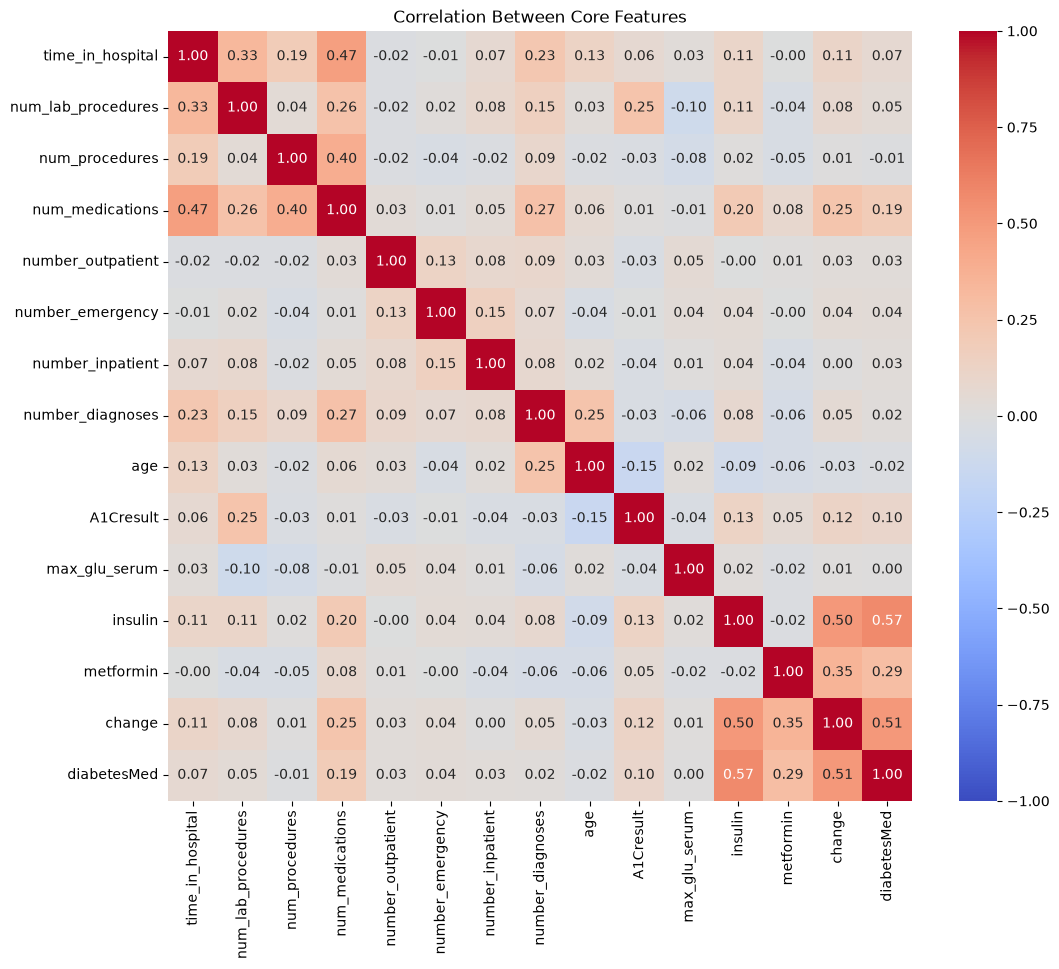

In [ ]:
00# Core features worth seeing side by side
core_cols = num_cols + ord_cols + ["insulin", "metformin", "change", "diabetesMed"]

corr = df[core_cols].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Core Features")
plt.savefig("../images/correlation_heatmap.png", bbox_inches="tight")
plt.show()

In [ ]:
# Top 10 most correlated pairs across every feature (target excluded)
corr_all = df.drop(columns="readmit_30").corr().abs()

# Keep only the upper triangle so each pair shows up once
upper = corr_all.where(np.triu(np.ones(corr_all.shape), k=1).astype(bool))
upper.stack().sort_values(ascending=False).head(10)

gender_Female          gender_Male               1.000000
race_AfricanAmerican   race_Caucasian            0.807020
admission_type_id_1    admission_source_id_7     0.719553
admission_source_id_1  admission_source_id_7     0.716648
admission_type_id_1    admission_source_id_1     0.606446
admission_type_id_3    admission_source_id_1     0.593911
insulin                diabetesMed               0.571259
payer_code_MC          payer_code_Unknown        0.550548
change                 diabetesMed               0.506067
admission_type_id_6    admission_source_id_17    0.502944
dtype: float64

In [64]:
# Gender_Male is just the opposite of gender_Female, so it's redundant
df = df.drop(columns=["gender_Male"])
df.shape

(69979, 133)

### Step 9: Check for clusters
**What:** Use K-Means on the scaled core features (without the target) to see if patients fall into natural groups.

**Why:** Before training a model, I wanted to see if patients naturally fall into groups on their own, without telling the algorithm who got readmitted.

**What I found:** No strong clusters. The elbow has no clear bend and silhouette scores stay low (0.12 to 0.16), so patients sit on a spectrum rather than in distinct types. Looking at 4 loose groups anyway, three split by diabetes medication (none, insulin, metformin), and one stands out as complex patients with long stays, lots of meds, and more diagnoses. That group is readmitted at 11.6% vs 9% overall, while the others sit at or below average. So complexity matters, but no group cleanly separates who comes back.

In [65]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Scale the core features so no column dominates just because of its units
X_clust = StandardScaler().fit_transform(df[core_cols])

In [66]:
# Try 2 to 8 clusters and score each one
k_range = range(2, 9)
inertias = []
sil_scores = []

for k in k_range:
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    labels = km.fit_predict(X_clust)
    inertias.append(km.inertia_)  # for the elbow method
    # Silhouette on a 5,000-row sample, since the full 70k is very slow
    sil_scores.append(silhouette_score(X_clust, labels, sample_size=5000, random_state=42))

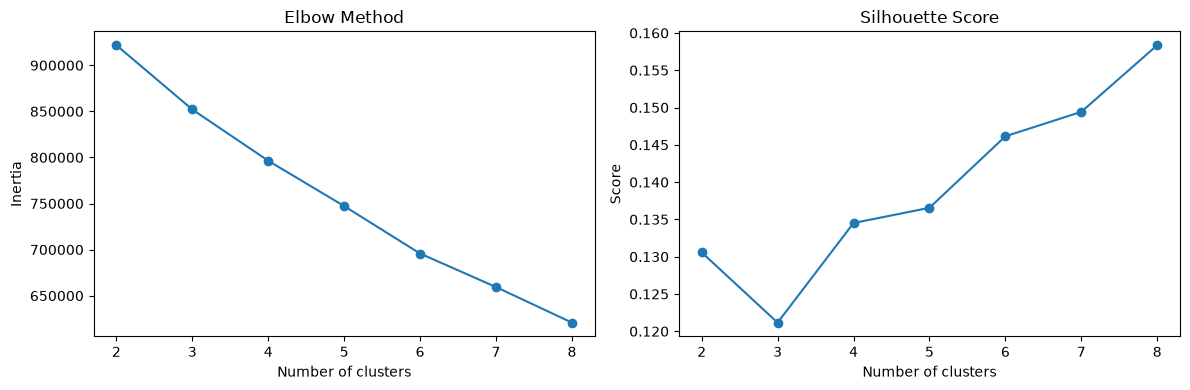

In [67]:
# Elbow and silhouette side by side
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_range, inertias, marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("Number of clusters")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_range, sil_scores, marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("Number of clusters")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.savefig("../images/cluster_scores.png", bbox_inches="tight")
plt.show()

In [68]:
# Fit the final model with 4 clusters
km = KMeans(n_clusters=4, n_init=10, random_state=42)
cluster_labels = km.fit_predict(X_clust)

In [69]:
# Average of each core feature per cluster, to describe each group
profile = df[core_cols].copy()
profile["cluster"] = cluster_labels
profile.groupby("cluster").mean().round(2).T

cluster,0,1,2,3
time_in_hospital,3.76,3.18,7.77,3.68
num_lab_procedures,40.72,38.57,58.23,38.84
num_procedures,1.40,1.04,2.71,0.99
num_medications,12.48,13.03,25.21,15.12
number_outpatient,0.20,0.25,0.25,0.27
number_emergency,0.07,0.10,0.11,0.09
number_inpatient,0.14,0.16,0.26,0.12
number_diagnoses,7.12,6.95,8.31,6.83
age,6.10,5.99,6.29,5.84
A1Cresult,0.23,0.35,0.66,0.46


In [70]:
# How many patients in each cluster
pd.Series(cluster_labels).value_counts().sort_index()

0    16331
1    27288
2    13148
3    13212
Name: count, dtype: int64

In [71]:
# Readmission rate per cluster 
df.groupby(cluster_labels)["readmit_30"].mean().round(3)

0    0.075
1    0.091
2    0.116
3    0.079
Name: readmit_30, dtype: float64

### Step 10: Train/test split
**What:** Split the data into 80% training and 20% testing.

**Why:** The model needs to be tested on patients it has never seen, otherwise I'd just be grading its memory. Stratifying keeps the rare readmissions evenly split between both sets.

**What I found:** 55,983 patients for training and 13,996 for testing. Both sets have the same 9% readmission rate.

In [82]:
from sklearn.model_selection import train_test_split

# features (X) and target (y)
X = df.drop(columns="readmit_30")
y = df["readmit_30"]

# 80/20 split, stratified so both sets keep the same ~9% readmission rate
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

X_train.shape, X_test.shape

((55983, 132), (13996, 132))

In [83]:
# Confirm both sets have the same readmission rate
y_train.mean().round(3), y_test.mean().round(3)

(np.float64(0.09), np.float64(0.09))

### Step 11: Train the model
**What:** Train a logistic regression classifier inside a pipeline that scales the features first.

**Why:** Logistic regression predicts the probability of readmission and is easy to interpret. The pipeline scales features using only the training data, and balanced class weights make each readmission count more so the model doesn't just say "No" to everyone.

**What I found:** The model trained on all 132 features without errors.

In [85]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression

# Scale features, then classify. Balanced weights make the rare readmissions more important to the model.
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=1000)
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](132,)","['age','time_in_hospital','num_lab_procedures',..., 'admission_source_id_20','admission_source_id_22', 'admission_source_id_25']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,132
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


### Step 12: Test the model 

**What:** Predict readmission for the test patients and measure the results with a confusion matrix.

**Why:** Testing on patients the model has never seen shows how it would perform in the real world. Since only 9% of patients are readmitted, I judged it on recall and precision for the "Yes" class, not accuracy.

**What I found:** The model catches 52% of readmissions (recall), but only 14% of its "Yes" flags are correct (precision), so there are a lot of false alarms. Accuracy is 66%, lower than the 91% you'd get by always guessing "No," but that lazy model catches zero readmissions. AUC is 0.64, meaning the model ranks a readmitted patient as riskier than a non-readmitted one 64% of the time (50% would be a coin flip). It's real but modest signal, in line with how hard readmission is to predict.

In [86]:
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, roc_auc_score

# Predict yes/no for every test patient 
y_pred = model.predict(X_test)

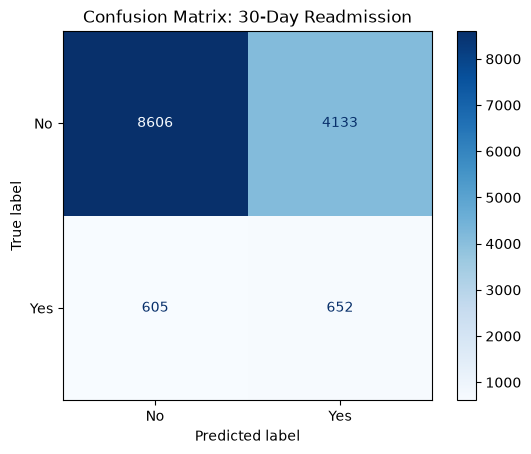

In [87]:
# Confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No", "Yes"], cmap="Blues"
)
plt.title("Confusion Matrix: 30-Day Readmission")
plt.savefig("../images/confusion_matrix.png", bbox_inches="tight")
plt.show()


In [88]:
# Precision, recall, and accuracy 
print(classification_report(y_test, y_pred, target_names=["No", "Yes"]))

              precision    recall  f1-score   support

          No       0.93      0.68      0.78     12739
         Yes       0.14      0.52      0.22      1257

    accuracy                           0.66     13996
   macro avg       0.54      0.60      0.50     13996
weighted avg       0.86      0.66      0.73     13996



In [89]:
# Always No baseline to compare against
print("Always-No accuracy:", round(1 - y_test.mean(), 3))

# AUC 
y_prob = model.predict_proba(X_test)[:, 1]
print("AUC:", round(roc_auc_score(y_test, y_prob), 3))

Always-No accuracy: 0.91
AUC: 0.641


### Step 13: What drives the predictions

**What:** Plot the model's strongest coefficients to see which features raise or lower readmission risk.

**Why:** A model is more useful (and trustworthy) when you can explain why it predicts what it does.

**What I found:** The biggest risk factor is the number of hospital stays in the past year, which is why I capped those patients instead of deleting them. Patients discharged to rehab, nursing, or other inpatient facilities are also more likely to come back, along with older patients and those with more diagnoses or ER visits. Being discharged home lowers risk. A few bars belong to tiny categories, like newborn admissions, so I wouldn't read much into those.

In [ ]:
# Map the codes to readable labels 
readable = {
    "discharge_disposition_id_1": "Discharged home",
    "discharge_disposition_id_3": "Discharged to nursing facility",
    "discharge_disposition_id_5": "Discharged to other inpatient care",
    "discharge_disposition_id_22": "Discharged to rehab facility",
    "discharge_disposition_id_23": "Discharged to long-term care hospital",
    "discharge_disposition_id_24": "Discharged to Medicaid nursing facility",
    "discharge_disposition_id_10": "Newborn sent to another hospital",
    "discharge_disposition_id_17": "Referred for outpatient care",
    "admission_type_id_4": "Admitted as newborn",
    "admission_type_id_7": "Admitted via trauma center",
    "admission_source_id_10": "Transfer from critical access hospital",
}


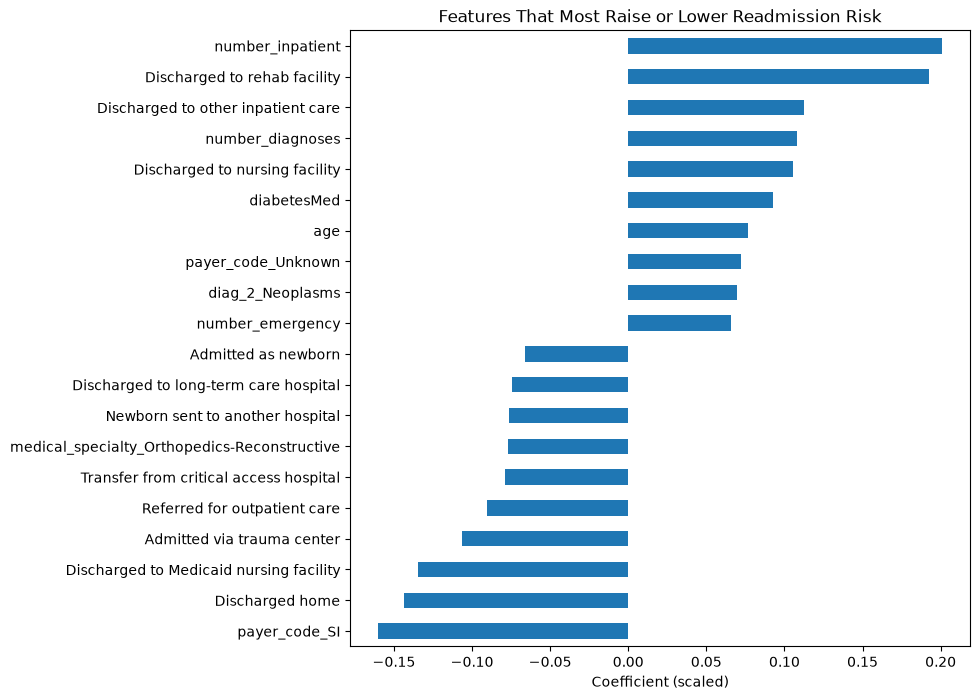

In [95]:
# Each feature's weight in the model 
coefs = pd.Series(model[-1].coef_[0], index=X_train.columns).sort_values()

# 10 strongest in each direction
top = pd.concat([coefs.head(10), coefs.tail(10)])

# swap code names for readable labels
top = top.rename(index=readable)

plt.figure(figsize=(8, 8))
top.plot(kind="barh")
plt.title("Features That Most Raise or Lower Readmission Risk")
plt.xlabel("Coefficient (scaled)")
plt.savefig("../images/feature_importance.png", bbox_inches="tight")
plt.show()

## Summary

**What I learned about the data:** These are diabetic patients, but most were admitted for other reasons, mainly heart problems. Only 9% came back within 30 days, so the classes are heavily imbalanced. The data needed real cleanup: hidden "?" missing values, "None" values that meant "test not done," repeat patients, and patients who died or went to hospice. Patients don't fall into clear clusters. The closest thing to a high-risk group was complex patients with long stays and lots of meds, readmitted at 11.6% vs 9% overall.

**How well the model worked:** The logistic regression catches about half of readmissions (52% recall), but only 1 in 7 of its flags is correct (14% precision). AUC is 0.64: real signal, but modest. Accuracy (66%) is lower than just guessing "No" every time (91%), which is exactly why accuracy is the wrong metric for imbalanced data.

**Why it's hard:** A lot of what drives readmission isn't in hospital records, like whether patients fill prescriptions, make follow-up appointments, or have support at home.

**Would it be useful?** As a screening tool, yes, if a flag triggers something cheap like a follow-up call. The strongest signals (prior hospital stays and where patients go after discharge) match what hospitals already watch for, which is a good sign the model learned something real.